# Oregon Statewide Wildlife-Vehicle Collision Analysis (2020–2026)

This notebook analyzes `Combined_Wildlife_Crashes_2020_2026.xlsx`, a harmonized statewide Oregon wildlife-vehicle collision dataset spanning **May 21, 2020 through August 30, 2026** (**1,632 unique crashes**, **1,693 vehicles**, and **2,424 involved people**).

### Key Structural & Analytical Notes
1. **Reporting Scope Shift:**
   * **2020–2024 (`WildlifeFatalCrashes_2020_2024.xlsx`):** Contains **15 fatal crashes only** (16 fatalities, 4 injuries). Non-fatal crashes are absent from this source.
   * **2025 (`StatewideCrashes_InvolvingWildlife_CDS501.csv`):** Full-year reporting across **all severities**, capturing **1,604 crashes** (3 fatal, 456 non-fatal injury, and 1,145 property damage only).
   * **2026 (Partial Year through Aug 30, 2026):** Contains **13 crashes** (4 fatal and 9 non-fatal injury; 0 PDO records appear in the 2026 slice).
2. **Lookup Text Columns:** Descriptive text columns (e.g., `CNTY_NM`, `WTHR_COND_LONG_DESC`, `LGT_COND_LONG_DESC`) are populated primarily for the 15 rows from 2020–2024, whereas 2025–2026 records store numeric codes (`CNTY_ID`, `WTHR_COND_CD`, etc.).
3. **Methodology:** Multi-year trend comparisons use the consistent `Fatal_Crashes_2020_2026` subset ($n = 22$), while full-severity seasonal and hourly distributions filter to the complete **2025 calendar year** ($n = 1,604$).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

filepath = 'Combined_Wildlife_Crashes_2020_2026.xlsx'
xls = pd.ExcelFile(filepath)
print("Available sheets:", xls.sheet_names)

crashes = pd.read_excel(filepath, sheet_name='All_Crashes_2020_2026')
fatals = pd.read_excel(filepath, sheet_name='Fatal_Crashes_2020_2026')
vehicles = pd.read_excel(filepath, sheet_name='Vehicles_2025_2026')
participants = pd.read_excel(filepath, sheet_name='Participants_2025_2026')
field_guide = pd.read_excel(filepath, sheet_name='Field_Mapping_Guide')

print(f"Loaded All_Crashes: {crashes.shape}, Fatal_Crashes: {fatals.shape}, Vehicles: {vehicles.shape}, Participants: {participants.shape}")

Available sheets: ['Executive Summary', 'Fatal_Crashes_2020_2026', 'All_Crashes_2020_2026', 'Vehicles_2025_2026', 'Participants_2025_2026', 'Field_Mapping_Guide']
Loaded All_Crashes: (1632, 99), Fatal_Crashes: (22, 99), Vehicles: (1678, 26), Participants: (1787, 36)


## 1. Annual Breakdown by Severity & Casualty Totals
Examining crash counts across years and reporting scopes, along with total human fatalities and injury severities (Level A = incapacitating, Level B = non-incapacitating, Level C = possible injury).

In [2]:
# Annual breakdown by severity
severity_by_year = crashes.groupby(['CRASH_YR_NO', 'REPORTING_SCOPE', 'CRASH_SVRTY_LONG_DESC']).size().unstack(fill_value=0)
severity_by_year['Total_Crashes'] = severity_by_year.sum(axis=1)

# Add fatality and injury counts per year
casualties_by_year = crashes.groupby('CRASH_YR_NO')[['TOT_FATAL_CNT', 'TOT_INJ_CNT', 'TOT_INJ_LVL_A_CNT', 'TOT_INJ_LVL_B_CNT', 'TOT_INJ_LVL_C_CNT']].sum()
annual_summary = severity_by_year.join(casualties_by_year)
display(annual_summary)

print("\nOverall Dataset Totals:")
display(crashes[['TOT_VHCL_CNT', 'TOT_FATAL_CNT', 'TOT_INJ_CNT', 'TOT_INJ_LVL_A_CNT', 'TOT_INJ_LVL_B_CNT', 'TOT_INJ_LVL_C_CNT', 'TOT_PER_INVLV_CNT']].sum().to_frame('Total'))

,,Fatal,Non-Fatal Injury,Property Damage Only (PDO),Total_Crashes,TOT_FATAL_CNT,TOT_INJ_CNT,TOT_INJ_LVL_A_CNT,TOT_INJ_LVL_B_CNT,TOT_INJ_LVL_C_CNT
CRASH_YR_NO,REPORTING_SCOPE,,,,,,,,,
2020,Fatal Only (2020-2024),4,0,0,4,5,2,0,2,0
2021,Fatal Only (2020-2024),3,0,0,3,3,0,0,0,0
2023,Fatal Only (2020-2024),5,0,0,5,5,2,0,1,1
2024,Fatal Only (2020-2024),3,0,0,3,3,0,0,0,0
2025,All Severities (2025-2026),3,456,1145,1604,3,568,72,317,179
2026,All Severities (2025-2026),4,9,0,13,4,12,10,1,1



Overall Dataset Totals:


,Total
TOT_VHCL_CNT,1693
TOT_FATAL_CNT,23
TOT_INJ_CNT,584
TOT_INJ_LVL_A_CNT,82
TOT_INJ_LVL_B_CNT,321
TOT_INJ_LVL_C_CNT,181
TOT_PER_INVLV_CNT,2424


## 2. Temporal & Seasonal Dynamics (Monthly & Hourly Patterns)
Using the complete **2025 calendar year** ($n = 1,604$) for unbiased all-severity distributions alongside the **2020–2026 fatal crash series** ($n = 22$):
* **Autumn Rut Peak:** Crashes peak in **November (245; 15.3%)** and **October (187; 11.7%)**, with a secondary summer plateau from June through September.
* **Fatal Peak:** Half of all fatal crashes occur in **September (7)** and **August (4)**.
* **Crepuscular Spikes:** Hourly activity surges during dawn (**5:00–7:00 AM**) and dusk/early night (**5:00–9:00 PM**).

In [3]:
c2025 = crashes[crashes['CRASH_YR_NO'] == 2025].copy()

monthly_dist = pd.DataFrame({
    '2025_All_Severities': c2025['CRASH_MO_NO'].value_counts().sort_index(),
    '2025_Share_%': (c2025['CRASH_MO_NO'].value_counts(normalize=True).sort_index() * 100).round(2),
    '2020_2026_Fatal_Crashes': fatals['CRASH_MO_NO'].value_counts().sort_index()
}).fillna({'2020_2026_Fatal_Crashes': 0})
monthly_dist['2020_2026_Fatal_Crashes'] = monthly_dist['2020_2026_Fatal_Crashes'].astype(int)
print("=== Monthly Distribution ===")
display(monthly_dist)

hourly_dist = pd.DataFrame({
    '2025_All_Severities': c2025['CRASH_HR_NO'].value_counts().sort_index(),
    '2020_2026_Fatal_Crashes': fatals['CRASH_HR_NO'].value_counts().sort_index()
}).fillna(0).astype(int)
print("=== Hourly Distribution (Hour 99 = Unknown) ===")
display(hourly_dist)

=== Monthly Distribution ===


,2025_All_Severities,2025_Share_%,2020_2026_Fatal_Crashes
CRASH_MO_NO,,,
1,86,5.36,1
2,64,3.99,0
3,71,4.43,0
4,84,5.24,1
5,122,7.61,2
6,171,10.66,2
7,169,10.54,3
8,140,8.73,4
9,168,10.47,7


=== Hourly Distribution (Hour 99 = Unknown) ===


,2025_All_Severities,2020_2026_Fatal_Crashes
CRASH_HR_NO,,
0,55,3
1,57,0
2,40,1
3,30,1
4,37,1
5,84,0
6,102,0
7,90,1
8,70,1


## 3. Contributing Risk Factors: All Crashes vs. Fatal Crashes
Comparing behavioral and roadway factors between routine wildlife crashes and fatal collisions reveals sharp contrasts in impairment, speeding, and roadway departure.

In [4]:
flags = ['DRUG_INVLV_FLG', 'ALCHL_INVLV_FLG', 'MJ_INVLV_FLG', 'CRASH_SPEED_INVLV_FLG', 'OFF_RDWY_FLG']
risk_comparison = pd.DataFrame({
    'All_Crashes_Count (n=1632)': crashes[flags].sum(),
    'All_Crashes_%': (crashes[flags].mean() * 100).round(2),
    'Fatal_Crashes_Count (n=22)': fatals[flags].sum(),
    'Fatal_Crashes_%': (fatals[flags].mean() * 100).round(2)
})
display(risk_comparison)

# Check vehicle types in 2025-2026 (Code 1 = Passenger Car/Light Truck, Code 9 = Motorcycle)
fatal_25_26_ids = fatals[fatals['CRASH_YR_NO'].isin([2025, 2026])]['CRASH_ID']
print("\n=== Vehicle Types in 2025–2026 (All vs. Fatal Crashes) ===")
veh_comp = pd.DataFrame({
    'All_2025_2026_Vehicles': vehicles['Vehicle Type Code'].value_counts(),
    'Fatal_2025_2026_Vehicles': vehicles[vehicles['Crash ID'].isin(fatal_25_26_ids)]['Vehicle Type Code'].value_counts()
}).fillna(0).astype(int)
display(veh_comp.head(10))

,All_Crashes_Count (n=1632),All_Crashes_%,Fatal_Crashes_Count (n=22),Fatal_Crashes_%
DRUG_INVLV_FLG,12,0.74,8,36.36
ALCHL_INVLV_FLG,27,1.65,7,31.82
MJ_INVLV_FLG,1,0.06,0,0.00
CRASH_SPEED_INVLV_FLG,112,6.86,7,31.82
OFF_RDWY_FLG,329,20.16,7,31.82



=== Vehicle Types in 2025–2026 (All vs. Fatal Crashes) ===


,All_2025_2026_Vehicles,Fatal_2025_2026_Vehicles
Vehicle Type Code,,
1,1582,6
4,27,0
5,8,0
6,2,0
7,2,0
9,52,3
11,3,0
13,1,0
99,1,0


## 4. Species, Roadway Environment & Geographic Hotspots
Decoding available county IDs, speed limits, lighting conditions, primary crash events, and top highway corridors.

In [5]:
# Map known county names from 2020-2024 rows to numeric CNTY_IDs
cnty_map = crashes.dropna(subset=['CNTY_NM']).set_index('CNTY_ID')['CNTY_NM'].to_dict()
crashes['COUNTY_CLEAN'] = crashes['CNTY_NM'].fillna(crashes['CNTY_ID'].map(cnty_map)).fillna('County_ID_' + crashes['CNTY_ID'].astype(str))

print("=== Top 10 Counties (All Crashes) ===")
display(crashes['COUNTY_CLEAN'].value_counts().head(10).to_frame('Crash_Count'))

print("=== Top Highways (HWY_NO, excluding blank) ===")
hwy_clean = crashes['HWY_NO'].astype(str).str.strip()
display(hwy_clean[hwy_clean != ''].value_counts().head(10).to_frame('Crash_Count'))

print("=== Posted Speed Limits (POST_SPEED_LMT_VAL) ===")
spd_clean = crashes['POST_SPEED_LMT_VAL'].astype(str).str.strip()
display(spd_clean[~spd_clean.isin(['', '<Null>', 'nan'])].value_counts().head(10).to_frame('Crash_Count'))

print("=== Primary Crash Event 1 Code (35 = Deer/Elk, 34 = Other Wild Animal) ===")
display(crashes['CRASH_EVNT_1_CD'].value_counts().head(8).to_frame('Crash_Count'))

print("=== Lighting Condition Code (3 = Darkness no street lights, 1 = Daylight) ===")
display(crashes['LGT_COND_CD'].value_counts().to_frame('Crash_Count'))

=== Top 10 Counties (All Crashes) ===


,Crash_Count
COUNTY_CLEAN,
Jackson,118
Douglas,95
Deschutes,95
County_ID_4,90
County_ID_18,90
Lane,82
County_ID_3,81
County_ID_30,71
Linn,67


=== Top Highways (HWY_NO, excluding blank) ===


,Crash_Count
HWY_NO,
009,100
001,88
004,74
006,67
092,47
007,37
091,34
047,29
002,27


=== Posted Speed Limits (POST_SPEED_LMT_VAL) ===


,Crash_Count
POST_SPEED_LMT_VAL,
55,765
65,193
45,108
70,90
35,47
50,41
40,22
25,19
30,10


=== Primary Crash Event 1 Code (35 = Deer/Elk, 34 = Other Wild Animal) ===


,Crash_Count
CRASH_EVNT_1_CD,
35,1350
34,98
79,73
128,24
62,20
43,15
53,8
58,6


=== Lighting Condition Code (3 = Darkness no street lights, 1 = Daylight) ===


,Crash_Count
LGT_COND_CD,
3,804
1,518
4,113
5,107
2,79
0,11


## 5. Summary Visualization Dashboard
Four-panel summary visual illustrating:
1. 2025 monthly crash counts by severity
2. 2025 hourly crash distribution highlighting dawn and dusk/night peaks
3. Annual fatal wildlife crashes and human fatalities (2020–2026)
4. Contributing factor comparison between all crashes and fatal crashes

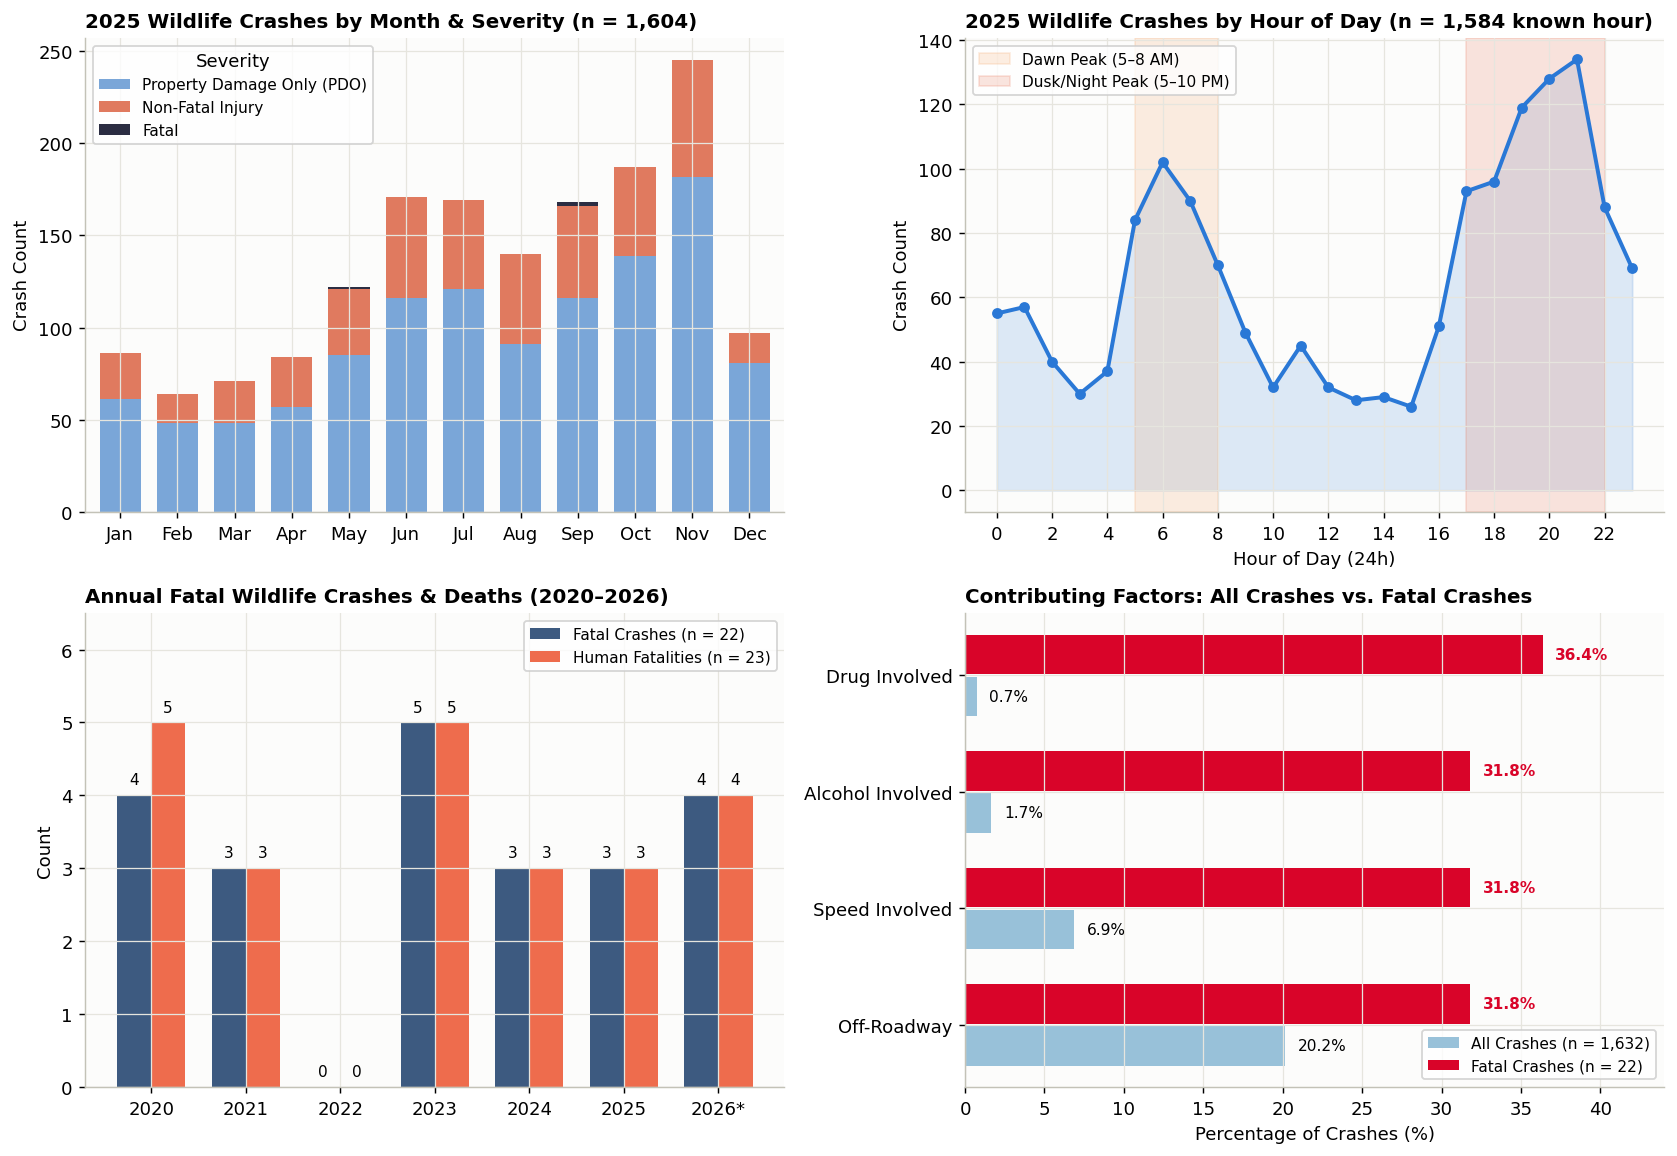

In [6]:
plt.rcParams.update({
    'figure.dpi': 130,
    'figure.facecolor': '#ffffff',
    'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e6e5de',
    'grid.linewidth': 0.7
})

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Monthly distribution (2025 Full Year All Severities)
mo_counts = c2025.groupby(['CRASH_MO_NO', 'CRASH_SVRTY_LONG_DESC']).size().unstack(fill_value=0)
mo_counts = mo_counts[['Property Damage Only (PDO)', 'Non-Fatal Injury', 'Fatal']]
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
mo_counts.plot(kind='bar', stacked=True, ax=axes[0, 0], color=['#7aa6d8', '#e07a5f', '#2b2d42'], width=0.72)
axes[0, 0].set_title('2025 Wildlife Crashes by Month & Severity (n = 1,604)', fontsize=11, fontweight='bold', loc='left')
axes[0, 0].set_xticklabels(months, rotation=0)
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('Crash Count')
axes[0, 0].legend(title='Severity', frameon=True, facecolor='white', fontsize=8.5)

# 2. Hourly distribution (2025 Full Year)
hr_counts = c2025[c2025['CRASH_HR_NO'] < 24]['CRASH_HR_NO'].value_counts().reindex(range(24), fill_value=0)
axes[0, 1].plot(hr_counts.index, hr_counts.values, marker='o', color='#2a78d6', linewidth=2.2, markersize=5)
axes[0, 1].fill_between(hr_counts.index, hr_counts.values, color='#2a78d6', alpha=0.15)
axes[0, 1].axvspan(5, 8, color='#f4a261', alpha=0.18, label='Dawn Peak (5–8 AM)')
axes[0, 1].axvspan(17, 22, color='#e76f51', alpha=0.18, label='Dusk/Night Peak (5–10 PM)')
axes[0, 1].set_title('2025 Wildlife Crashes by Hour of Day (n = 1,584 known hour)', fontsize=11, fontweight='bold', loc='left')
axes[0, 1].set_xticks(range(0, 24, 2))
axes[0, 1].set_xlabel('Hour of Day (24h)')
axes[0, 1].set_ylabel('Crash Count')
axes[0, 1].legend(frameon=True, facecolor='white', fontsize=8.5)

# 3. Fatal Crashes by Year (2020-2026 Consistent Scope)
yr_fatal = fatals.groupby('CRASH_YR_NO').agg(crashes=('CRASH_ID', 'count'), fatalities=('TOT_FATAL_CNT', 'sum')).reindex(range(2020, 2027), fill_value=0)
x = np.arange(len(yr_fatal))
w = 0.36
axes[1, 0].bar(x - w/2, yr_fatal['crashes'], width=w, label='Fatal Crashes (n = 22)', color='#3d5a80')
axes[1, 0].bar(x + w/2, yr_fatal['fatalities'], width=w, label='Human Fatalities (n = 23)', color='#ee6c4d')
axes[1, 0].set_title('Annual Fatal Wildlife Crashes & Deaths (2020–2026)', fontsize=11, fontweight='bold', loc='left')
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels([str(y) + ('*' if y==2026 else '') for y in yr_fatal.index])
axes[1, 0].set_ylabel('Count')
axes[1, 0].set_ylim(0, 6.5)
for i, (c_val, f_val) in enumerate(zip(yr_fatal['crashes'], yr_fatal['fatalities'])):
    axes[1, 0].text(i - w/2, c_val + 0.15, str(c_val), ha='center', fontsize=8.5)
    axes[1, 0].text(i + w/2, f_val + 0.15, str(f_val), ha='center', fontsize=8.5)
axes[1, 0].legend(frameon=True, facecolor='white', fontsize=8.5)

# 4. Risk Factors: All Crashes vs. Fatal Crashes (%)
factors = ['Drug Involved', 'Alcohol Involved', 'Speed Involved', 'Off-Roadway']
all_pcts = [
    crashes['DRUG_INVLV_FLG'].mean() * 100,
    crashes['ALCHL_INVLV_FLG'].mean() * 100,
    crashes['CRASH_SPEED_INVLV_FLG'].mean() * 100,
    crashes['OFF_RDWY_FLG'].mean() * 100
]
fatal_pcts = [
    fatals['DRUG_INVLV_FLG'].mean() * 100,
    fatals['ALCHL_INVLV_FLG'].mean() * 100,
    fatals['CRASH_SPEED_INVLV_FLG'].mean() * 100,
    fatals['OFF_RDWY_FLG'].mean() * 100
]
y_pos = np.arange(len(factors))
axes[1, 1].barh(y_pos + 0.18, all_pcts, height=0.34, label='All Crashes (n = 1,632)', color='#98c1d9')
axes[1, 1].barh(y_pos - 0.18, fatal_pcts, height=0.34, label='Fatal Crashes (n = 22)', color='#d90429')
axes[1, 1].set_yticks(y_pos)
axes[1, 1].set_yticklabels(factors)
axes[1, 1].invert_yaxis()
axes[1, 1].set_xlabel('Percentage of Crashes (%)')
axes[1, 1].set_title('Contributing Factors: All Crashes vs. Fatal Crashes', fontsize=11, fontweight='bold', loc='left')
axes[1, 1].set_xlim(0, 44)
for i, (a_v, f_v) in enumerate(zip(all_pcts, fatal_pcts)):
    axes[1, 1].text(a_v + 0.8, i + 0.18, f'{a_v:.1f}%', va='center', fontsize=8.5)
    axes[1, 1].text(f_v + 0.8, i - 0.18, f'{f_v:.1f}%', va='center', fontsize=8.5, fontweight='bold', color='#d90429')
axes[1, 1].legend(frameon=True, facecolor='white', fontsize=8.5, loc='lower right')

plt.tight_layout()
plt.show()